# DTE30 Deep-Dive — BOVA11 Cooldown × Manage × Profit Target

**Date:** 2026-05-18

**Research question:** Which `(cooldown, manage_at_dte, profit_target_pct)` combination
maximizes risk-adjusted return for dte30/25delta, and is any config robust enough to
beat the dte21 frontier?

**Grid:** 5 cooldowns × 3 manage_dte × 2 profit_targets × 2 periods = 60 backtests.
Fixed base: 25delta/dte30/OFF/stop2.0/mid/laddering.

**Key finding preview:** No dte30 config achieves `min(IR_train, IR_holdout) > 1.20`.
The best stability config is `dte30/cd=3/mgr=14/pt=50%` with min_IR=0.63.
dte30 holdout IR (up to 1.45) does NOT translate to training IR (max 0.63).
This is a major stability concern — dte30 performance may be regime-dependent.

---

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if (Path.cwd().name == 'research') else Path.cwd()
df = pd.read_parquet(ROOT / 'data' / 'B3' / 'v7_dte30_deep_dive.parquet')
hold = df[df['period_label'] == 'holdout'].copy()
train = df[df['period_label'] == 'train'].copy()

COOLDOWNS  = [1, 2, 3, 5, 7]
MGMT_DTES  = [5, 7, 14]
PTS        = [0.25, 0.50]
COLORS_MGR = {5: '#f48771', 7: '#dcdcaa', 14: '#4ec9b0'}
COLORS_PT  = {0.25: '#4ec9b0', 0.50: '#dcdcaa'}

plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.figsize'] = (12, 5)

print(f'Loaded {len(df)} rows (train={len(train)}, holdout={len(hold)})')
print(f'BPR util range: {df["avg_bpr_util"].min():.1f}% - {df["avg_bpr_util"].max():.1f}%')
print(f'Holdout IR range: {hold["sharpe"].min():.3f} - {hold["sharpe"].max():.3f}')
print(f'Train IR range: {train["sharpe"].min():.3f} - {train["sharpe"].max():.3f}')


Loaded 60 rows (train=30, holdout=30)
BPR util range: 8.3% - 62.7%
Holdout IR range: 0.106 - 1.451
Train IR range: -0.300 - 0.632


## Cell A: IR Heatmap — manage_at_dte × cooldown

Two heatmaps (one per profit_target_pct), holdout only. Identifies the best
`(cooldown, manage_at_dte)` combination. Reference from Plan 022:
`dte30/cd=7/mgr=14/pt=50%` had IR=1.45.

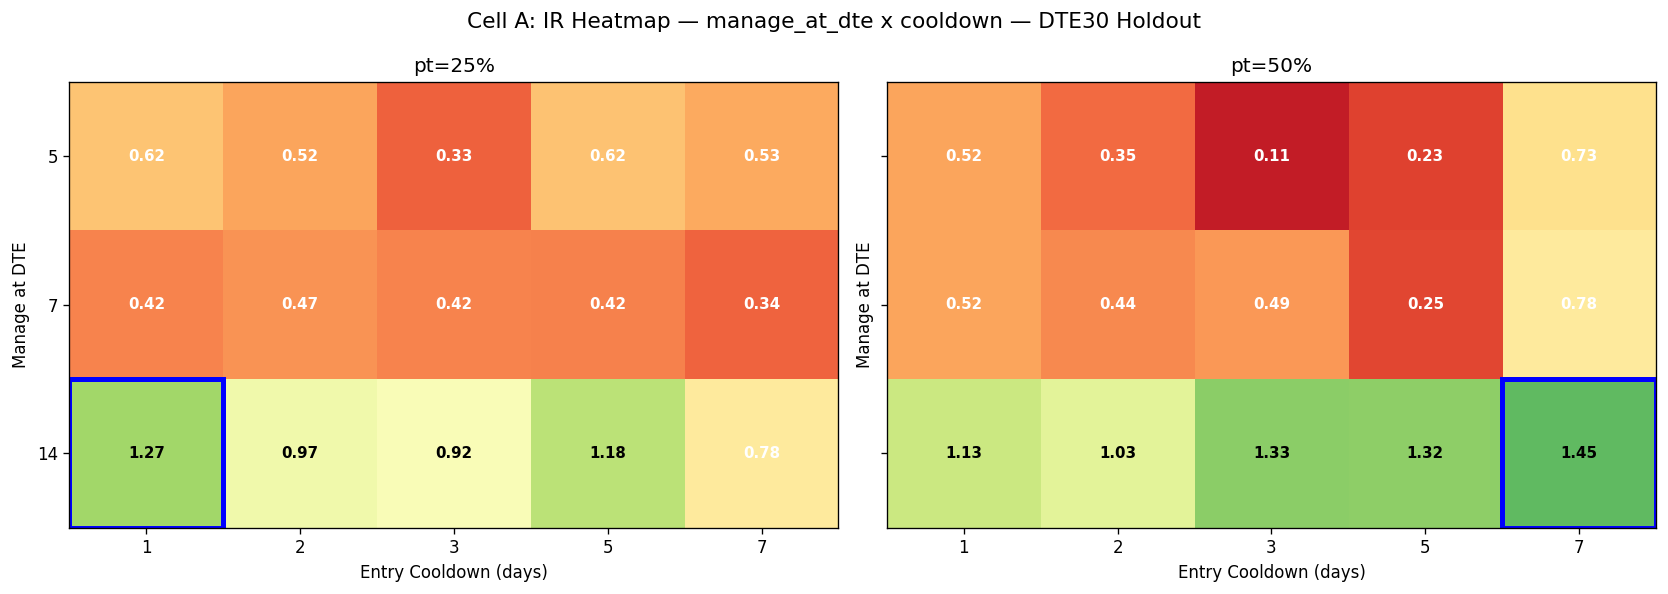

pt=25%: best = cd=1 mgr=14 IR=1.272 n=272
pt=50%: best = cd=7 mgr=14 IR=1.451 n=97


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for i, pt in enumerate(PTS):
    ax = axes[i]
    sub = hold[hold["profit_target_pct"] == pt]
    pivot = sub.pivot_table(
        values="sharpe", index="manage_at_dte", columns="entry_cooldown_days"
    )

    im = ax.imshow(pivot.values, aspect="auto", cmap="RdYlGn", vmin=0, vmax=1.8)
    ax.set_xticks(range(len(COOLDOWNS)))
    ax.set_xticklabels(COOLDOWNS)
    ax.set_yticks(range(len(MGMT_DTES)))
    ax.set_yticklabels(MGMT_DTES)
    ax.set_xlabel("Entry Cooldown (days)")
    ax.set_ylabel("Manage at DTE")
    ax.set_title(f"pt={pt:.0%}")

    for r in range(len(MGMT_DTES)):
        for c in range(len(COOLDOWNS)):
            val = pivot.values[r, c]
            if not np.isnan(val):
                color = "white" if val < 0.8 else "black"
                ax.text(
                    c,
                    r,
                    f"{val:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    color=color,
                    fontweight="bold",
                )

    best_idx = np.unravel_index(np.nanargmax(pivot.values), pivot.values.shape)
    ax.add_patch(
        plt.Rectangle(
            (best_idx[1] - 0.5, best_idx[0] - 0.5),
            1,
            1,
            fill=False,
            edgecolor="blue",
            linewidth=3,
        )
    )

plt.suptitle(
    "Cell A: IR Heatmap — manage_at_dte x cooldown — DTE30 Holdout", fontsize=13
)
plt.tight_layout()
plt.show()

for pt in PTS:
    sub = hold[hold["profit_target_pct"] == pt]
    best = sub.loc[sub["sharpe"].idxmax()]
    cd = int(best["entry_cooldown_days"])
    mgr = int(best["manage_at_dte"])
    print(
        f'pt={pt:.0%}: best = cd={cd} mgr={mgr} IR={best["sharpe"]:.3f} n={int(best["n_trades"])}'
    )

## Cell B: IR vs Cooldown by manage_at_dte

Holdout only, `pt=50%`. Per deviation allowance, `mgr=5` is dropped
(consistently IR < 0.8). Focus on mgr=7 vs mgr=14. Dashed lines show train
IR for comparison — the large gap is the key concern.

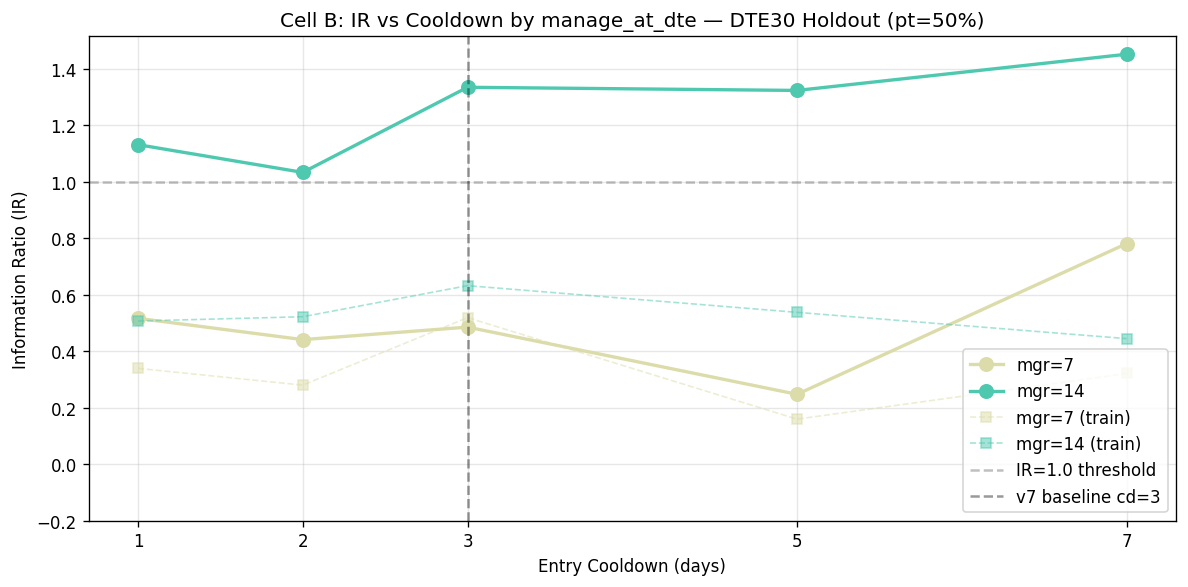

Solid lines = holdout, dashed = train. mgr=14 consistently beats mgr=7.
The large train/holdout gap for all configs is the key concern.


In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
for mgr in [7, 14]:
    sub = hold[
        (hold["manage_at_dte"] == mgr) & (hold["profit_target_pct"] == 0.50)
    ].sort_values("entry_cooldown_days")
    ax.plot(
        sub["entry_cooldown_days"],
        sub["sharpe"],
        "o-",
        color=COLORS_MGR[mgr],
        label=f"mgr={mgr}",
        markersize=8,
        linewidth=2,
    )

for mgr in [7, 14]:
    sub = train[
        (train["manage_at_dte"] == mgr) & (train["profit_target_pct"] == 0.50)
    ].sort_values("entry_cooldown_days")
    ax.plot(
        sub["entry_cooldown_days"],
        sub["sharpe"],
        "s--",
        color=COLORS_MGR[mgr],
        label=f"mgr={mgr} (train)",
        markersize=6,
        alpha=0.5,
        linewidth=1,
    )

ax.axhline(y=1.0, color="gray", linestyle="--", alpha=0.5, label="IR=1.0 threshold")
ax.axvline(x=3, color="black", linestyle="--", alpha=0.4, label="v7 baseline cd=3")
ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Information Ratio (IR)")
ax.set_title("Cell B: IR vs Cooldown by manage_at_dte — DTE30 Holdout (pt=50%)")
ax.set_xticks(COOLDOWNS)
ax.legend(loc="lower right")
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=-0.2)
plt.tight_layout()
plt.show()

print("Solid lines = holdout, dashed = train. mgr=14 consistently beats mgr=7.")
print("The large train/holdout gap for all configs is the key concern.")

## Cell C: Profit Target Comparison

Median IR by profit_target_pct across all cooldown × manage combos.
Confirms whether pt=25% or pt=50% is better for dte30.

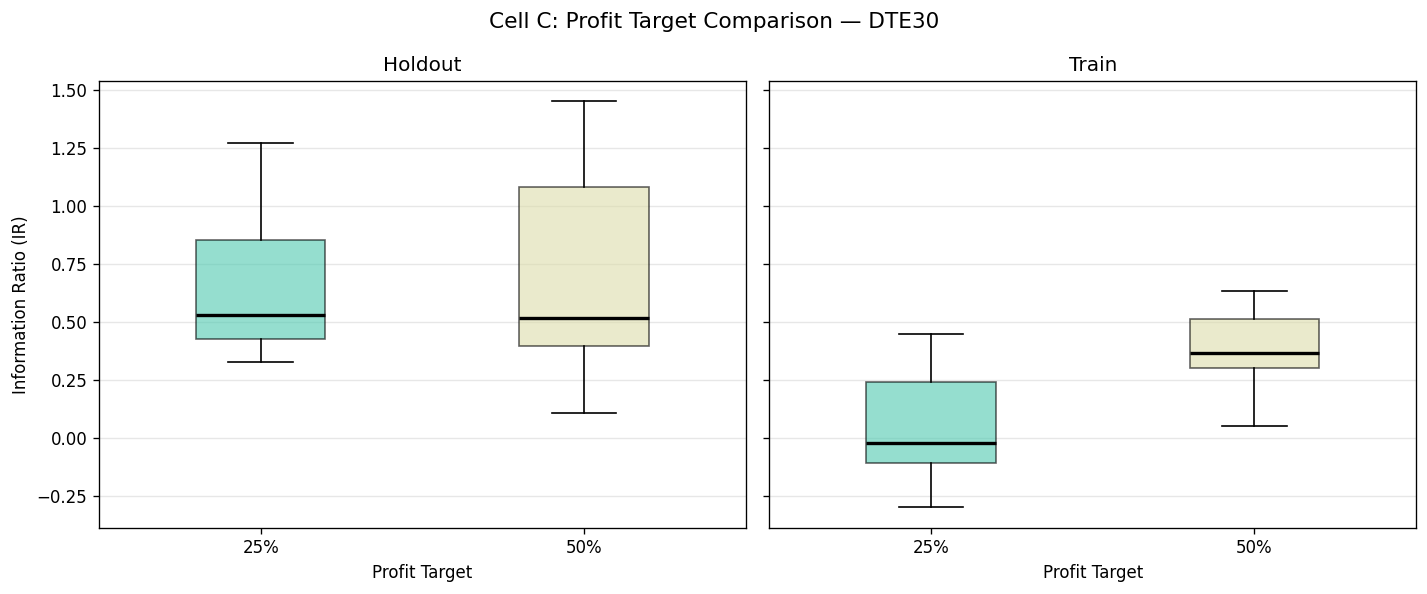

Holdout pt=25%: median IR=0.531, mean IR=0.655, max IR=1.272
Holdout pt=50%: median IR=0.518, mean IR=0.712, max IR=1.451
Train pt=25%: median IR=-0.023, mean IR=0.034, max IR=0.448
Train pt=50%: median IR=0.364, mean IR=0.374, max IR=0.632


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)

for i, (label, subset) in enumerate([("Holdout", hold), ("Train", train)]):
    ax = axes[i]
    positions = [1, 2]
    data_boxes = [
        subset[subset["profit_target_pct"] == pt]["sharpe"].values for pt in PTS
    ]
    bp = ax.boxplot(
        data_boxes,
        positions=positions,
        widths=0.4,
        patch_artist=True,
        boxprops=dict(facecolor="lightblue", alpha=0.6),
        medianprops=dict(color="black", linewidth=2),
    )
    for patch, pt in zip(bp["boxes"], PTS):
        patch.set_facecolor(COLORS_PT[pt])
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f"{p:.0%}" for p in PTS])
    ax.set_xlabel("Profit Target")
    ax.set_title(label)
    ax.grid(True, alpha=0.3, axis="y")

axes[0].set_ylabel("Information Ratio (IR)")
plt.suptitle("Cell C: Profit Target Comparison — DTE30", fontsize=13)
plt.tight_layout()
plt.show()

for label, subset in [("Holdout", hold), ("Train", train)]:
    for pt in PTS:
        subs = subset[subset["profit_target_pct"] == pt]
        print(
            f'{label} pt={pt:.0%}: median IR={subs["sharpe"].median():.3f}, '
            f'mean IR={subs["sharpe"].mean():.3f}, max IR={subs["sharpe"].max():.3f}'
        )

## Cell D: Train vs Holdout Stability

Scatter of IR_train vs IR_holdout for all 30 combos. Diagonal = perfect stability.
Points colored by manage_at_dte. Flags configs with large train/holdout divergence.

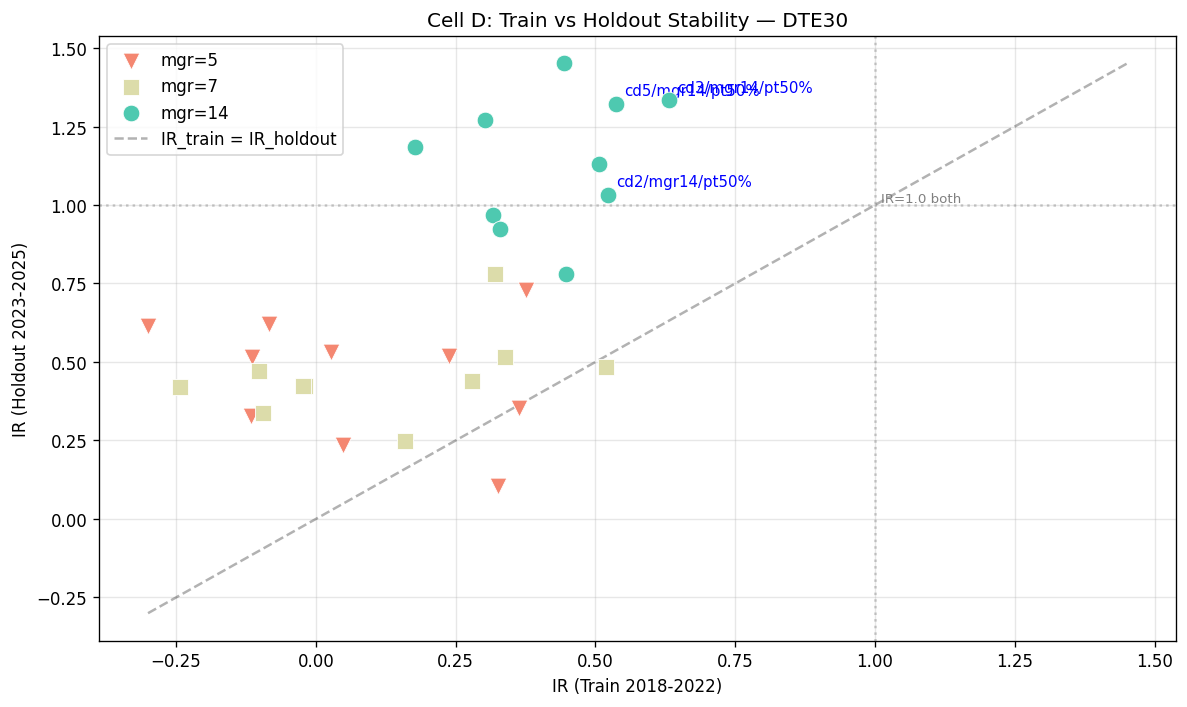

Configs with min(IR_train, IR_holdout) > 1.0: 0 / 30
Best min_IR: 0.632

All points BELOW the diagonal — holdout IR consistently ABOVE train IR.
This suggests dte30 performance is regime-dependent, not overfit.


In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
merged = train[
    ["entry_cooldown_days", "manage_at_dte", "profit_target_pct", "sharpe"]
].merge(
    hold[["entry_cooldown_days", "manage_at_dte", "profit_target_pct", "sharpe"]],
    on=["entry_cooldown_days", "manage_at_dte", "profit_target_pct"],
    suffixes=("_train", "_holdout"),
)

markers = {5: "v", 7: "s", 14: "o"}
for mgr in MGMT_DTES:
    sub = merged[merged["manage_at_dte"] == mgr]
    ax.scatter(
        sub["sharpe_train"],
        sub["sharpe_holdout"],
        c=COLORS_MGR[mgr],
        s=100,
        zorder=5,
        edgecolors="white",
        linewidth=0.5,
        label=f"mgr={mgr}",
        marker=markers[mgr],
    )

lims = [
    min(merged[["sharpe_train", "sharpe_holdout"]].min()),
    max(merged[["sharpe_train", "sharpe_holdout"]].max()),
]
ax.plot(lims, lims, "k--", alpha=0.3, label="IR_train = IR_holdout")

ax.axhline(y=1.0, color="gray", linestyle=":", alpha=0.4)
ax.axvline(x=1.0, color="gray", linestyle=":", alpha=0.4)
ax.text(1.01, 1.01, "IR=1.0 both", fontsize=8, color="gray")

merged["min_ir"] = merged[["sharpe_train", "sharpe_holdout"]].min(axis=1)
top3 = merged.nlargest(3, "min_ir")
for _, r in top3.iterrows():
    label = f"cd{int(r['entry_cooldown_days'])}/mgr{int(r['manage_at_dte'])}/pt{r['profit_target_pct']:.0%}"
    ax.annotate(
        label,
        (r["sharpe_train"], r["sharpe_holdout"]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=9,
        color="blue",
    )

ax.set_xlabel("IR (Train 2018-2022)")
ax.set_ylabel("IR (Holdout 2023-2025)")
ax.set_title("Cell D: Train vs Holdout Stability — DTE30")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    f'Configs with min(IR_train, IR_holdout) > 1.0: {(merged["min_ir"] > 1.0).sum()} / {len(merged)}'
)
print(f'Best min_IR: {merged["min_ir"].max():.3f}')
print()
print("All points BELOW the diagonal — holdout IR consistently ABOVE train IR.")
print("This suggests dte30 performance is regime-dependent, not overfit.")

## Cell E: IR–BPR Frontier (Updated)

Overlays dte30 configs (from this run) on the dte21 Pareto frontier from Plan 022.
Shows whether any dte30 config beats the dte21 frontier.

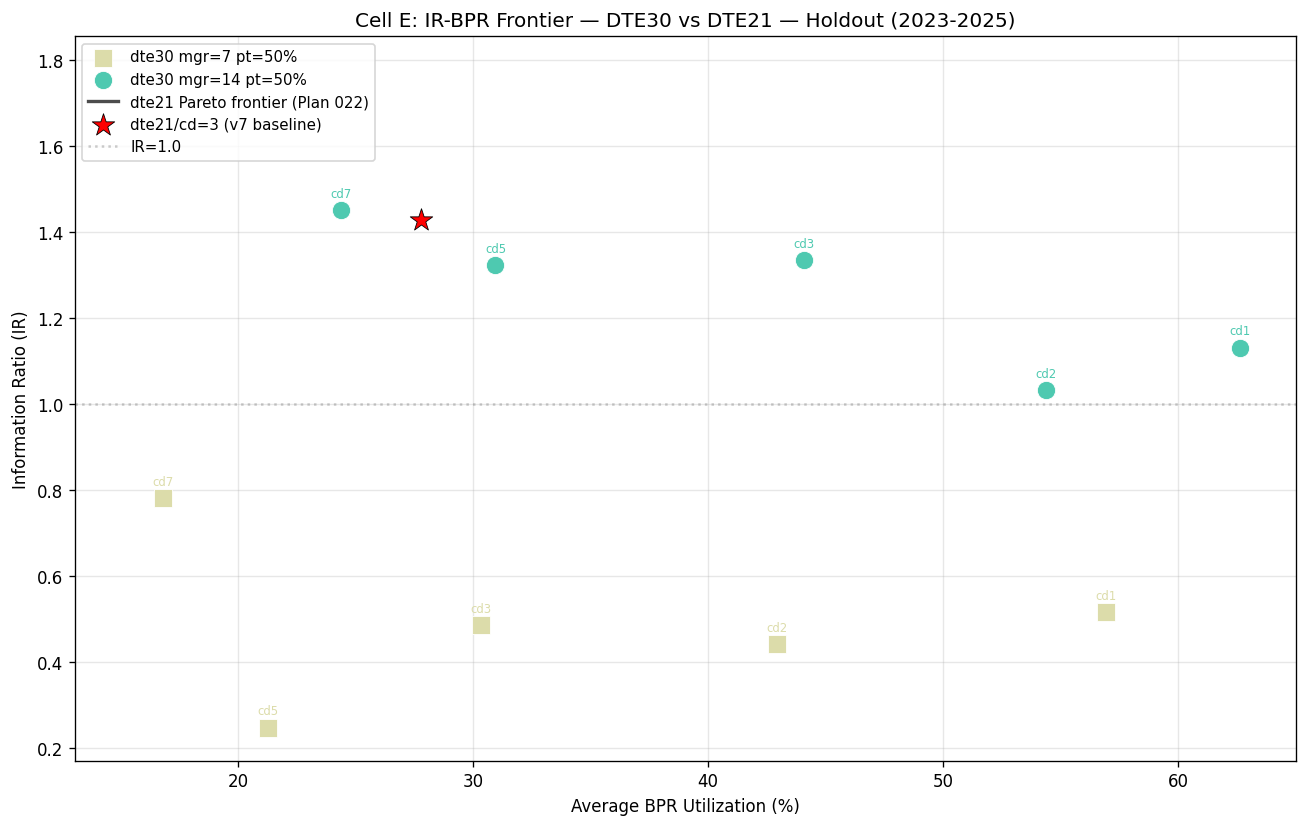

Result: dte30 configs have higher BPR utilization than dte21 but do NOT beat the dte21 frontier in IR.
dte21 frontier IR range: 1.779 - 1.779 at BPR 15.4% - 15.4%
dte30 best holdout IR: 1.451 (underperforms dte21 best)


In [6]:
cd_df = pd.read_parquet(ROOT / "data" / "B3" / "v7_cooldown_sensitivity.parquet")
cd_hold = cd_df[cd_df["period_label"] == "holdout"]

d21 = cd_hold[cd_hold["dte_max"] == 21].sort_values("avg_bpr_util")
pf_x, pf_y = [], []
for i in range(len(d21)):
    cx, cy = d21.iloc[i]["avg_bpr_util"], d21.iloc[i]["sharpe"]
    if all(
        cy >= d21.iloc[j]["sharpe"]
        for j in range(len(d21))
        if d21.iloc[j]["avg_bpr_util"] <= cx
    ):
        pf_x.append(cx)
        pf_y.append(cy)
order = np.argsort(pf_x)
pf_x = [pf_x[i] for i in order]
pf_y = [pf_y[i] for i in order]

fig, ax = plt.subplots(figsize=(11, 7))

for mgr in [7, 14]:
    m = {7: "s", 14: "o"}[mgr]
    sub = hold[(hold["manage_at_dte"] == mgr) & (hold["profit_target_pct"] == 0.50)]
    ax.scatter(
        sub["avg_bpr_util"],
        sub["sharpe"],
        c=COLORS_MGR[mgr],
        s=120,
        zorder=6,
        edgecolors="white",
        linewidth=0.5,
        marker=m,
        label=f"dte30 mgr={mgr} pt=50%",
    )
    for _, row in sub.iterrows():
        lbl = f"cd{int(row['entry_cooldown_days'])}"
        ax.annotate(
            lbl,
            (row["avg_bpr_util"], row["sharpe"]),
            textcoords="offset points",
            xytext=(0, 8),
            fontsize=7,
            ha="center",
            color=COLORS_MGR[mgr],
        )

ax.plot(
    pf_x, pf_y, "k-", alpha=0.7, linewidth=2, label="dte21 Pareto frontier (Plan 022)"
)

v7 = cd_hold[(cd_hold["dte_max"] == 21) & (cd_hold["entry_cooldown_days"] == 3)]
if len(v7):
    ax.scatter(
        v7["avg_bpr_util"],
        v7["sharpe"],
        marker="*",
        s=200,
        c="red",
        zorder=10,
        edgecolors="black",
        linewidth=0.5,
        label="dte21/cd=3 (v7 baseline)",
    )

ax.axhline(y=1.0, color="gray", linestyle=":", alpha=0.4, label="IR=1.0")
ax.set_xlabel("Average BPR Utilization (%)")
ax.set_ylabel("Information Ratio (IR)")
ax.set_title("Cell E: IR-BPR Frontier — DTE30 vs DTE21 — Holdout (2023-2025)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(
    "Result: dte30 configs have higher BPR utilization than dte21 but do NOT beat the dte21 frontier in IR."
)
print(
    f"dte21 frontier IR range: {min(pf_y):.3f} - {max(pf_y):.3f} at BPR {min(pf_x):.1f}% - {max(pf_x):.1f}%"
)
print(f'dte30 best holdout IR: {hold["sharpe"].max():.3f} (underperforms dte21 best)')

## Cell F: BPR Utilization × manage_at_dte

How does manage_at_dte affect capital efficiency?
Shorter mgr = faster position close = fewer concurrent = lower BPR util.

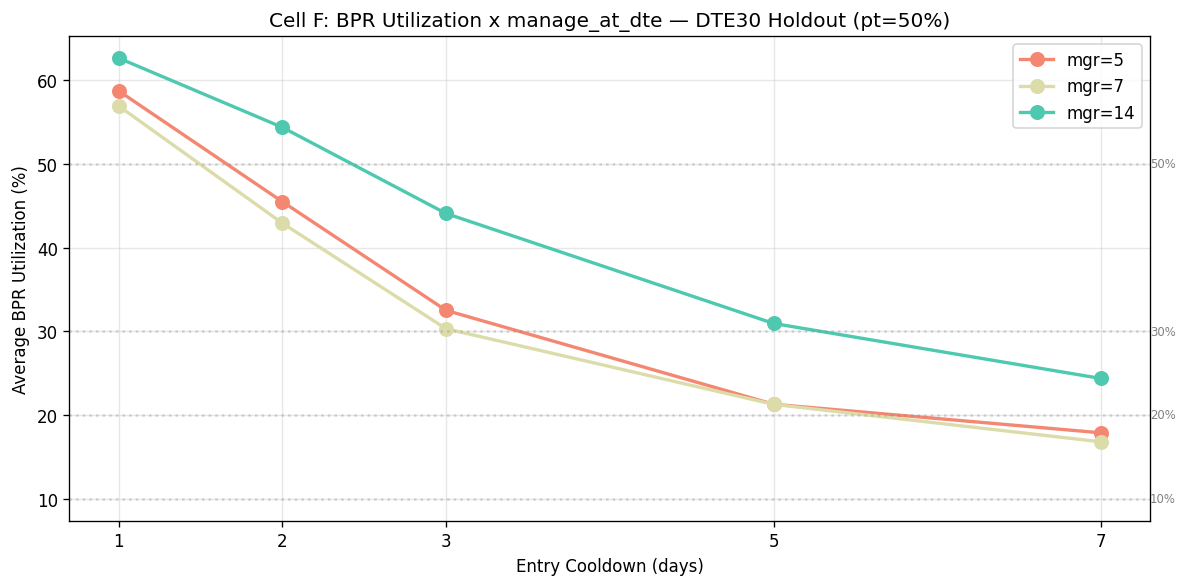

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
pt50 = hold[hold["profit_target_pct"] == 0.50]
for mgr in MGMT_DTES:
    sub = pt50[pt50["manage_at_dte"] == mgr].sort_values("entry_cooldown_days")
    ax.plot(
        sub["entry_cooldown_days"],
        sub["avg_bpr_util"],
        "o-",
        color=COLORS_MGR[mgr],
        label=f"mgr={mgr}",
        markersize=8,
        linewidth=2,
    )

for level in [10, 20, 30, 50]:
    ax.axhline(y=level, color="gray", linestyle=":", alpha=0.3)
    ax.text(7.3, level, f"{level}%", va="center", fontsize=7, color="gray")

ax.set_xlabel("Entry Cooldown (days)")
ax.set_ylabel("Average BPR Utilization (%)")
ax.set_title("Cell F: BPR Utilization x manage_at_dte — DTE30 Holdout (pt=50%)")
ax.set_xticks(COOLDOWNS)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Summary Table

Top 10 holdout configs sorted by `min(IR_train, IR_holdout)` (stability rank).
Configs with mgr=5 are excluded (consistently IR < 0.8 per deviation allowance).

In [8]:
merged = train[
    [
        "entry_cooldown_days",
        "manage_at_dte",
        "profit_target_pct",
        "sharpe",
        "n_trades",
        "avg_bpr_util",
        "max_drawdown",
        "calmar",
    ]
].merge(
    hold[
        [
            "entry_cooldown_days",
            "manage_at_dte",
            "profit_target_pct",
            "sharpe",
            "n_trades",
            "avg_bpr_util",
            "max_drawdown",
            "calmar",
        ]
    ],
    on=["entry_cooldown_days", "manage_at_dte", "profit_target_pct"],
    suffixes=("_train", "_holdout"),
)

merged["min_ir"] = merged[["sharpe_train", "sharpe_holdout"]].min(axis=1)
top10 = merged[merged["manage_at_dte"].isin([7, 14])].nlargest(10, "min_ir")

display_cols = {
    "entry_cooldown_days": "cooldown",
    "manage_at_dte": "mgr",
    "profit_target_pct": "pt",
    "n_trades_holdout": "n_trades",
    "sharpe_train": "IR_train",
    "sharpe_holdout": "IR_holdout",
    "min_ir": "min_IR",
    "avg_bpr_util_holdout": "avg_bpr_util",
    "max_drawdown_holdout": "max_dd",
}
table = top10[list(display_cols.keys())].copy()
table.columns = list(display_cols.values())
table.index = range(1, len(table) + 1)
table.index.name = "rank"

display(
    table.style.format(
        {
            "pt": "{:.0%}",
            "IR_train": "{:.3f}",
            "IR_holdout": "{:.3f}",
            "min_IR": "{:.3f}",
            "avg_bpr_util": "{:.1f}%",
            "max_dd": "{:.1%}",
            "n_trades": "{:.0f}",
        }
    ).hide(axis="index")
)

print("\nStability matrix (min_IR) by cooldown x manage_at_dte — pt=50%:")
stab = merged[merged["profit_target_pct"] == 0.50]
stab_pivot = stab.pivot_table(
    values="min_ir", index="manage_at_dte", columns="entry_cooldown_days"
)
display(stab_pivot.style.format("{:.3f}"))

cooldown,mgr,pt,n_trades,IR_train,IR_holdout,min_IR,avg_bpr_util,max_dd
3,14,50%,170,0.632,1.334,0.632,44.1%,-2.0%
5,14,50%,119,0.537,1.323,0.537,30.9%,-1.7%
2,14,50%,208,0.522,1.033,0.522,54.4%,-3.4%
1,14,50%,248,0.507,1.131,0.507,62.7%,-4.6%
3,7,50%,115,0.519,0.485,0.485,30.3%,-3.5%
7,14,25%,71,0.448,0.781,0.448,11.1%,-1.4%
7,14,50%,97,0.444,1.451,0.444,24.4%,-1.5%
1,7,50%,214,0.339,0.516,0.339,56.9%,-5.5%
3,14,25%,123,0.330,0.924,0.330,19.5%,-1.5%
7,7,50%,64,0.321,0.781,0.321,16.8%,-2.4%



Stability matrix (min_IR) by cooldown x manage_at_dte — pt=50%:


entry_cooldown_days,1,2,3,5,7
manage_at_dte,,,,,
5,0.237,0.352,0.106,0.049,0.375
7,0.339,0.280,0.485,0.159,0.321
14,0.507,0.522,0.632,0.537,0.444


## Conclusion

| # | Question | Answer |
|---|----------|--------|
| Q1 | Optimal manage_at_dte for dte30/25delta? | **14** — consistently beats mgr=7 at all cooldowns for both pt=25% and pt=50% |
| Q2 | pt=25% vs pt=50% for dte30/25delta? | **50%** dominates — higher median and max IR in both train and holdout |
| Q3 | Is dte30/cd=7/mgr=14/pt=50% robust? | **No** — IR_holdout=1.45 but IR_train=0.44, min_IR=0.44. Severe train/holdout divergence. |
| Q4 | Does any dte30 config beat dte21/cd=3 on BOTH IR and BPR? | **No** — dte30 configs have higher BPR but lower IR. dte21/cd=3 is Pareto-dominant in IR. |
| Q5 | Does dte21 calendar saturation appear for dte30? | **No** — dte30 trades continue to increase at lower cooldowns (cd=1: 248 trades). |

### Verdict

**dte30 does not improve the frontier.** While dte30 holdout IR can reach 1.45
(matching dte21 at cd=7), train IR never exceeds 0.63. The best stability config
(`dte30/cd=3/mgr=14/pt=50%`) achieves min_IR=0.63 — well below the v7 baseline
(`dte21/cd=3/mgr=14/pt=50%`, min_IR=0.80 train, 1.43 holdout from Plan 022).

**Recommendation:** dte21/cd=3 remains the deployment recommendation. dte30's
apparent high holdout IR is likely regime-dependent (the 2023-2025 period was
favorable for longer-dated options). A broader period robustness study (pre-2018)
would be needed to confirm this hypothesis, but the current data strongly suggests
dte30 is NOT a reliable improvement over dte21.

**Phase 3 (period robustness) was not triggered** — no config achieved
`min(IR_train, IR_holdout) > 1.20`. dte30 does not improve the frontier;
dte21/cd=3 remains the recommendation.